In [105]:
import os
import sys

os.environ["TORCH_CUDA_ARCH_LIST"] = "7.5"  # Varies by GPU

from pathlib import Path

import numpy as np
import pandas as pd

import PIL
from PIL import Image

import pickle
import setuptools
import torch
import requests

In [88]:
if not Path("stylegan2-ada-pytorch").exists():
    !git clone https://github.com/NVlabs/stylegan2-ada-pytorch.git

Cloning into 'stylegan2-ada-pytorch'...
remote: Enumerating objects: 131, done.
remote: Counting objects: 100% (2/2), done.
remote: Compressing objects: 100% (2/2), done.
remote: Total 131 (delta 0), reused 0 (delta 0), pack-reused 129 (from 2)
Receiving objects: 100% (131/131), 1.13 MiB | 7.93 MiB/s, done.
Resolving deltas: 100% (57/57), done.


In [89]:
!wget -nc https://nvlabs-fi-cdn.nvidia.com/stylegan2-ada-pytorch/pretrained/ffhq.pkl

--2026-11-19 17:10:37--  https://nvlabs-fi-cdn.nvidia.com/stylegan2-ada-pytorch/pretrained/ffhq.pkl
Resolving nvlabs-fi-cdn.nvidia.com (nvlabs-fi-cdn.nvidia.com)... 13.249.180.7, 13.249.180.122, 13.249.180.12, ...
Connecting to nvlabs-fi-cdn.nvidia.com (nvlabs-fi-cdn.nvidia.com)|13.249.180.7|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 381624121 (364M) [binary/octet-stream]
Saving to: ‘ffhq.pkl’

ffhq.pkl            100%[===================>] 363.94M   112MB/s    in 3.3s    

2026-11-19 17:10:41 (110 MB/s) - ‘ffhq.pkl’ saved [381624121/381624121]



In [90]:
stylegan_dir = Path("stylegan2-ada-pytorch").resolve()
sys.path.insert(0, str(stylegan_dir))

import dnnlib
import legacy
from training import networks

In [91]:
torch.cuda.is_available()

True

In [ ]:
with open("ffhq.pkl", "rb") as f:
    G = pickle.load(f)["G_ema"].cuda()

In [ ]:
z = torch.randn([1, G.z_dim]).cuda()
c = None  # class labels (not used in this example)

z = torch.from_numpy(np.random.RandomState(1999).randn(1, G.z_dim)).cuda()
w = G.mapping(z, c, truncation_psi=0.80)

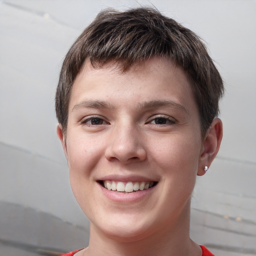

In [94]:
img = G.synthesis(w, noise_mode="const", force_fp32=True)
img = (img.permute(0, 2, 3, 1) * 127.5 + 128).clamp(0, 255).to(torch.uint8)
PIL.Image.fromarray(img[0].cpu().numpy(), "RGB").resize((256, 256))

## Generate Stimuli

In [ ]:
def generate_stimuli(G, z, c, truncation_psi=0.80):
    w = G.mapping(z, c, truncation_psi=truncation_psi)
    img = G.synthesis(w, noise_mode="const", force_fp32=True)
    img = (img.permute(0, 2, 3, 1) * 127.5 + 128).clamp(0, 255).to(torch.uint8)
    return w, PIL.Image.fromarray(img[0].cpu().numpy(), "RGB").resize((256, 256))


images = []
latents = []
for i in range(10):
    z = torch.from_numpy(np.random.RandomState(i).randn(1, G.z_dim)).cuda()
    w, img = generate_stimuli(G, z, c)
    images.append(img)
    latents.append(w.cpu().numpy())

## Collect Behavioral Data

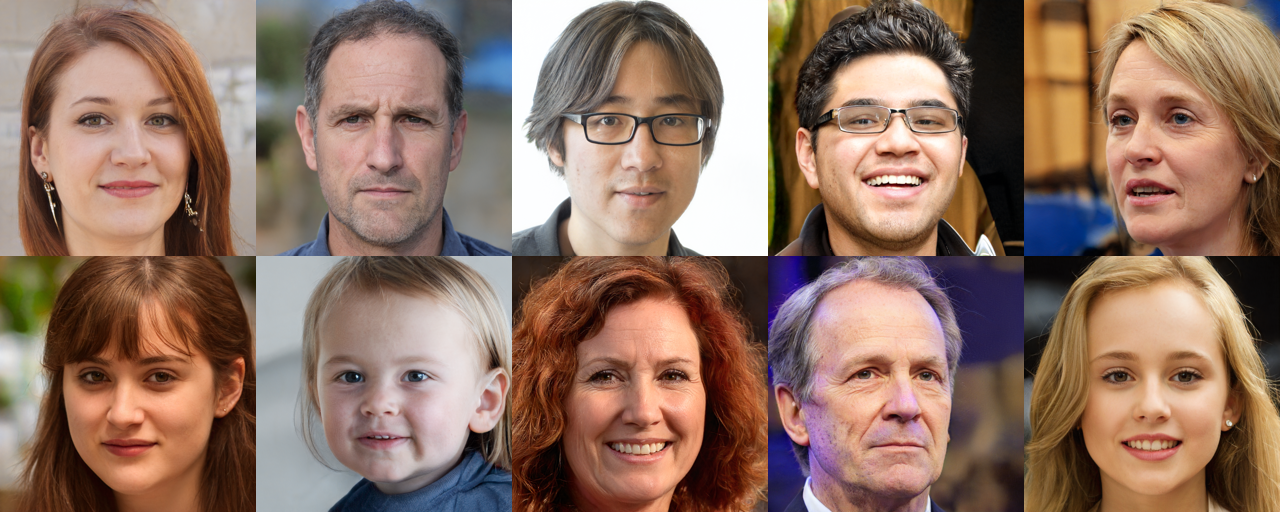

In [96]:
# Display the 10 images in a grid
grid = Image.new("RGB", (256 * 5, 256 * 2))
for i, img in enumerate(images):
    grid.paste(img, (256 * (i % 5), 256 * (i // 5)))

display(grid)

In [97]:
responses = [1, -1, -1, -1, 1, 1, 0, 1, -1, 1]
# responses = [1, -1, -1, 1, -1, -1, 0, 1, -1, 1]

## Produce Idiosyncratic Model

In [98]:
# Step 0. Average of all latents to act as the "base"
average_latent = np.mean(latents, axis=0)

# Step 1. Average latents of all "positive" responses
positive_latents = np.array(
    [latents[i] for i in range(len(responses)) if responses[i] == 1]
)
average_positive_latent = np.mean(positive_latents, axis=0)

# Step 2. Average latents of all "negative" responses
negative_latents = np.array(
    [latents[i] for i in range(len(responses)) if responses[i] == -1]
)
average_negative_latent = np.mean(negative_latents, axis=0)

In [ ]:
def compute_idiosyncratic_model(positive, negative, base, sd=1, eps=1e-8):
    # Get base magnitude for later unnormalization
    base_magnitude = np.linalg.norm(base)

    # Normalize the other vectors
    diff = positive - negative
    diff_norm = np.linalg.norm(diff) + eps
    normalized_diff = diff / diff_norm

    normalized_base = base / (np.linalg.norm(base) + eps)

    # Combine normalized vectors
    combined = normalized_base + (normalized_diff * sd)

    pos_neg_out = combined * base_magnitude

    return pos_neg_out

In [100]:
computed_idiosyncratic_model = compute_idiosyncratic_model(
    average_positive_latent, average_negative_latent, average_latent, sd=1.5
)

Produce an image from the model.

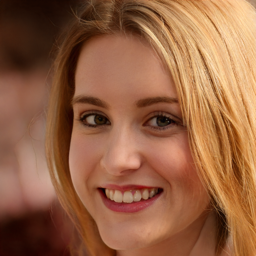

In [101]:
model_w = torch.as_tensor(
    computed_idiosyncratic_model,
    dtype=torch.float32,
    device="cuda",
)

with torch.no_grad():
    img = G.synthesis(model_w, noise_mode="const", force_fp32=True)

img = (img.permute(0, 2, 3, 1) * 127.5 + 128).clamp(0, 255).to(torch.uint8)
PIL.Image.fromarray(img[0].cpu().numpy(), "RGB").resize((256, 256))

We can create a "strip" of images to visualize the model from -1.5 to +1.5 standard deviations.  The following code will generate a strip of 5 images based on the computed idiosyncratic model.

In [102]:
np.linspace(-1.5, 1.5, 7)

array([-1.5, -1. , -0.5,  0. ,  0.5,  1. ,  1.5])

In [103]:
grid = Image.new("RGB", (256 * 7, 256))
for i, sd in enumerate(np.linspace(-1.5, 1.5, 7)):
    model_w = torch.as_tensor(
        compute_idiosyncratic_model(
            average_positive_latent, average_negative_latent, average_latent, sd=sd
        ),
        dtype=torch.float32,
        device="cuda",
    )
    with torch.no_grad():
        img = G.synthesis(model_w, noise_mode="const", force_fp32=True)
    img = (img.permute(0, 2, 3, 1) * 127.5 + 128).clamp(0, 255).to(torch.uint8)
    grid.paste(
        PIL.Image.fromarray(img[0].cpu().numpy(), "RGB").resize((256, 256)),
        (256 * i, 0),
    )

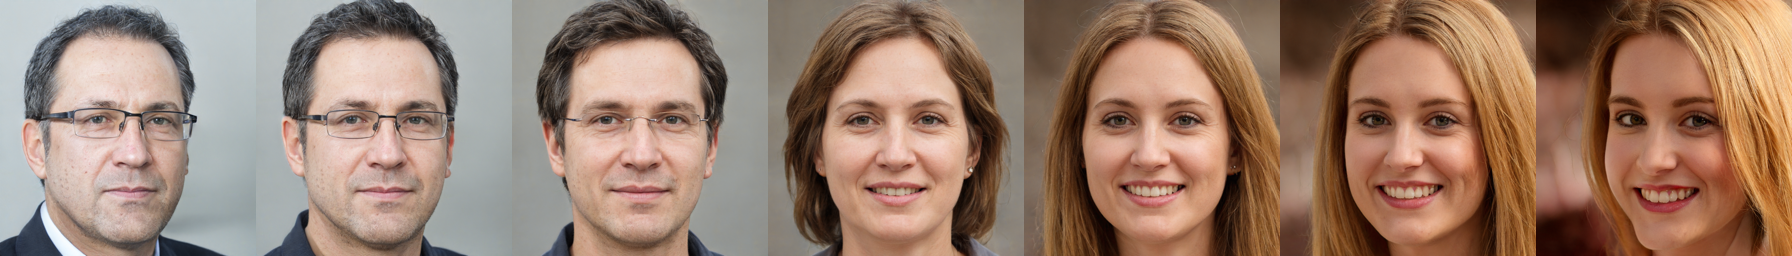

In [104]:
display(grid)